
# Day 3 — MoCo Self-Supervised Pretraining

## 1. 实验目标

本实验在 CIFAR-10 数据集上训练 Momentum Contrast（MoCo）自监督学习模型，研究模型能否在不使用类别标签的情况下学习有效的视觉表征。

### 核心组件

- **Query Encoder**：通过反向传播更新参数。
- **Key Encoder**：使用 Exponential Moving Average（EMA）更新参数。
- **Negative Queue**：使用 FIFO 队列维护负样本特征。
- **InfoNCE Loss**：通过区分正样本与负样本学习视觉表征。

### 训练流程

$$
x \rightarrow (x_q,x_k)
$$

$$
q=f_{\theta_q}(x_q), \qquad
k=f_{\theta_k}(x_k)
$$

$$
\mathcal{L}_{\mathrm{InfoNCE}}
=
-\log
\frac{\exp(q^\top k^+/\tau)}
{\exp(q^\top k^+/\tau)+
\sum_{i=1}^{K}\exp(q^\top k_i^-/\tau)}
$$

### 实验计划

1. 验证 MPS 运行环境。
2. 加载 CIFAR-10 并构造双视图增强。
3. 初始化 MoCo 模型与优化器。
4. 运行小规模 Smoke Test。
5. 正式训练并记录 Loss。
6. 保存模型 Checkpoint。


### 1.验证运行环境

In [1]:

import sys
import torch
from pathlib import Path

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())
print("Working directory:", Path.cwd())

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)


Python: 3.13.9
PyTorch: 2.11.0
MPS available: True
Working directory: /Users/liziwen/Documents/GitHub/contrastive-representation-lab/notebooks
Device: mps


In [2]:

import sys
from pathlib import Path

cwd = Path.cwd().resolve()

if (cwd / "src").is_dir():
    project_root = cwd
elif (cwd.parent / "src").is_dir():
    project_root = cwd.parent
else:
    raise FileNotFoundError("Cannot locate src/ directory")

sys.path.insert(0, str(project_root))

from src.moco import MoCo, ContrastiveEncoder

print("MoCo module imported successfully!")


MoCo module imported successfully!


In [3]:
# Small Forward Test

import torch

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

model = MoCo(
    feature_dim=128,
    queue_size=1024,
    momentum=0.999,
    temperature=0.2
).to(device)

# Simulate two augmented views of 4 images
im_q = torch.randn(4, 3, 32, 32, device=device)
im_k = torch.randn(4, 3, 32, 32, device=device)

model.train()

loss, logits = model(im_q, im_k)

print("Loss:", loss.item())
print("Logits shape:", logits.shape)
print("Queue pointer:", model.queue_ptr.item())


Loss: 2.4724721908569336
Logits shape: torch.Size([4, 1025])
Queue pointer: 4


In [4]:
# Data Loading

from torchvision import datasets, transforms
from torch.utils.data import Dataset, DataLoader

# Two independent augmented views of the same image
class TwoViewDataset(Dataset):
    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, label = self.base_dataset[index]
        im_q = self.transform(image)
        im_k = self.transform(image)
        return im_q, im_k, label


contrastive_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        32, scale=(0.2, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(0.4, 0.4, 0.4, 0.1)
    ], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    transforms.ToTensor()
])

# Use the dataset already downloaded on Day 1
base_dataset = datasets.CIFAR10(
    root=str(project_root / "data"),
    train=True,
    download=False,
    transform=None
)

train_dataset = TwoViewDataset(
    base_dataset,
    contrastive_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    drop_last=True
)

im_q, im_k, labels = next(iter(train_loader))

print("Dataset size:", len(train_dataset))
print("Query shape:", im_q.shape)
print("Key shape:", im_k.shape)
print("Labels shape:", labels.shape)


Dataset size: 50000
Query shape: torch.Size([64, 3, 32, 32])
Key shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])


**Smoke Test** 
***Step 1:*** 初始化模型和Optimizer



In [6]:

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

# Reinitialize model after the random forward test
torch.manual_seed(42)

model = MoCo(
    feature_dim=128,
    queue_size=1024,
    momentum=0.999,#EMA 更新 Encoder
    temperature=0.2
).to(device)

optimizer = torch.optim.SGD(
    model.encoder_q.parameters(),
    lr=0.03,
    momentum=0.9,
    weight_decay=1e-4
)#平滑梯度优化

print("Device:", device)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
))
print("Model initialized successfully!")


Device: mps
Trainable parameters: 11497152
Model initialized successfully!


In [5]:
# 单个epoch的训练函数
def train_one_epoch(
    model,
    loader,
    optimizer,
    device,
    max_steps=None
):
    model.train()
    total_loss = 0.0
    losses = []

    start_time = time.time()

    for step, (im_q, im_k, _) in enumerate(loader):

        if max_steps is not None and step >= max_steps:
            break

        im_q = im_q.to(device)
        im_k = im_k.to(device)

        optimizer.zero_grad(set_to_none=True)

        # Forward: InfoNCE + EMA + Negative Queue
        loss, logits = model(im_q, im_k)

        # Backpropagate through Query Encoder
        loss.backward()
        optimizer.step()

        loss_value = loss.item()
        total_loss += loss_value
        losses.append(loss_value)

        if (step + 1) % 5 == 0:
            print(
                f"Step {step+1:03d} | "
                f"Loss: {loss_value:.4f} | "
                f"Queue ptr: {model.queue_ptr.item()}"
            )

    elapsed = time.time() - start_time
    avg_loss = total_loss / max(len(losses), 1)

    print(
        f"\nAverage Loss: {avg_loss:.4f} | "
        f"Elapsed: {elapsed:.1f}s"
    )

    return losses


In [7]:
# 20个Batch的 Smoke Test
smoke_losses = train_one_epoch(
    model=model,
    loader=train_loader,
    optimizer=optimizer,
    device=device,
    max_steps=20
)


Step 005 | Loss: 5.5405 | Queue ptr: 320
Step 010 | Loss: 6.3479 | Queue ptr: 640
Step 015 | Loss: 6.7597 | Queue ptr: 960
Step 020 | Loss: 6.8567 | Queue ptr: 256

Average Loss: 6.0145 | Elapsed: 2.7s


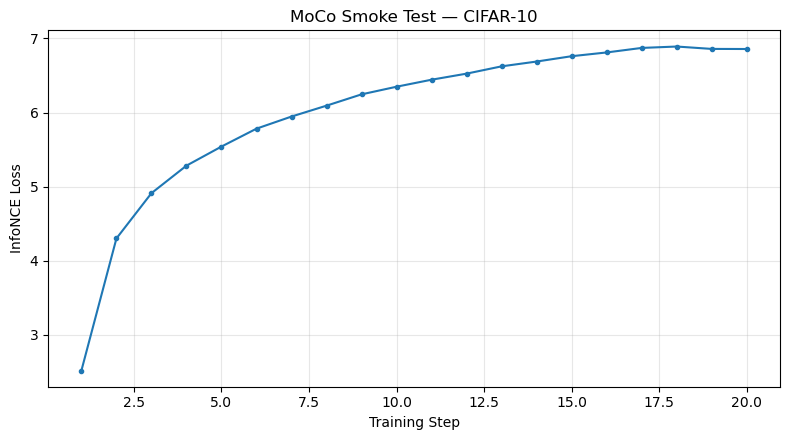

In [8]:
# 绘制训练损失
plt.figure(figsize=(8, 4.5))
plt.plot(
    range(1, len(smoke_losses) + 1),
    smoke_losses,
    marker="o",
    markersize=3
)

plt.xlabel("Training Step")
plt.ylabel("InfoNCE Loss")
plt.title("MoCo Smoke Test — CIFAR-10")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:
# 检查模型是否更新参数
print("Number of training steps:", len(smoke_losses))
print("Initial loss:", round(smoke_losses[0], 4))
print("Final loss:", round(smoke_losses[-1], 4))

print("All losses finite:", bool(
    torch.isfinite(torch.tensor(smoke_losses)).all()
))

print("Query Encoder trainable:", any(
    p.requires_grad for p in model.encoder_q.parameters()
))

print("Key Encoder frozen:", all(
    not p.requires_grad for p in model.encoder_k.parameters()
))


Number of training steps: 20
Initial loss: 2.5186
Final loss: 6.8567
All losses finite: True
Query Encoder trainable: True
Key Encoder frozen: True


In [ ]:
# 比较 Positive Similarity 和 Negative Similarity 的变化
#- Positive Similarity：同一张图片的两种增强视图有多相似。
#- Negative Similarity：Query 与队列中特征的平均相似度。
#- Hardest Negative Similarity：每个 Query 最相似的一个负样本有多相似。

model.eval()

im_q, im_k, _ = next(iter(train_loader))
im_q = im_q.to(device)
im_k = im_k.to(device)

with torch.no_grad():
    q = model.encoder_q(im_q)
    k = model.encoder_k(im_k)

    positive_sim = (q * k).sum(dim=1)
    negative_sim = q @ model.queue.detach()

print(
    "Positive similarity:",
    round(positive_sim.mean().item(), 4)
)

print(
    "Negative similarity:",
    round(negative_sim.mean().item(), 4)
)

print(
    "Hardest negative similarity:",
    round(negative_sim.max(dim=1).values.mean().item(), 4)
)


Positive similarity: 0.8718
Negative similarity: 0.8434
Hardest negative similarity: 0.9107


当前表征的正负样本区分能力较弱，整体余弦相似度较高

In [12]:
# 检查是否发生了坍塌

import torch

model.eval()

with torch.no_grad():
    # Use a small batch to test feature geometry
    sample_q = im_q[:32].to(device)

    features = model.encoder_q(sample_q)

    # Feature variance across samples
    feature_variance = features.var(
        dim=0, unbiased=False
    ).mean()

    # Pairwise cosine similarity
    similarity_matrix = features @ features.T

    n = features.size(0)

    # Avoid boolean masking on MPS
    off_diagonal_similarity = (
        similarity_matrix.sum()
        - similarity_matrix.diagonal().sum()
    ) / (n * (n - 1))

    # Transfer results to CPU together
    metrics = torch.stack([
        feature_variance,
        off_diagonal_similarity
    ]).detach().cpu().tolist()

print("Feature variance:", round(metrics[0], 6))
print("Mean off-diagonal similarity:", round(metrics[1], 4))


Feature variance: 0.000296
Mean off-diagonal similarity: 0.9609


In [13]:

from src.moco import ContrastiveEncoder

# A freshly initialized encoder as baseline
torch.manual_seed(123)

baseline_encoder = ContrastiveEncoder(
    feature_dim=128
).to(device)

baseline_encoder.eval()
model.eval()

sample_images = im_q[:32].to(device)

def feature_diagnostics(encoder, images):
    with torch.no_grad():
        z = encoder(images)
        n, d = z.shape

        variance = z.var(
            dim=0, unbiased=False
        ).mean()

        off_diag_sim = (
            z.sum(dim=0).square().sum()
            - z.square().sum()
        ) / (n * (n - 1))

        return (
            variance.item(),
            off_diag_sim.item()
        )

baseline_var, baseline_sim = feature_diagnostics(
    baseline_encoder, sample_images
)

trained_var, trained_sim = feature_diagnostics(
    model.encoder_q, sample_images
)

print("Random initialization:")
print(f"  Variance: {baseline_var:.6f}")
print(f"  Off-diagonal similarity: {baseline_sim:.4f}")

print("\nAfter 20 training steps:")
print(f"  Variance: {trained_var:.6f}")
print(f"  Off-diagonal similarity: {trained_sim:.4f}")


Random initialization:
  Variance: 0.000063
  Off-diagonal similarity: 0.9917

After 20 training steps:
  Variance: 0.000296
  Off-diagonal similarity: 0.9609


In [14]:
# 比较 Backbone 和 Projection Head的特征相似度
model.eval()

with torch.no_grad():
    images = im_q[:32].to(device)

    # 512-dimensional backbone representations
    h = model.encoder_q.backbone(images)
    h = torch.nn.functional.normalize(h, dim=1)

    # 128-dimensional projection representations
    z = model.encoder_q(images)

def mean_off_diagonal_similarity(features):
    features = torch.nn.functional.normalize(
        features, dim=1
    )

    n = features.shape[0]

    return (
        features.sum(dim=0).square().sum()
        - features.square().sum()
    ) / (n * (n - 1))

print(
    "Backbone (512D):",
    mean_off_diagonal_similarity(h).item()
)

print(
    "Projection (128D):",
    mean_off_diagonal_similarity(z).item()
)


Backbone (512D): 0.8953286409378052
Projection (128D): 0.9609280228614807



## 4. 正式预训练：MoCo on CIFAR-10

本阶段在 CIFAR-10 上进行多 Epoch 自监督预训练。

**实验目标：**

1. 观察 InfoNCE Loss 在更长训练周期中的变化。
2. 检查 Query Encoder 和 Momentum Encoder 的训练稳定性。
3. 保存模型权重和 Optimizer 状态，以支持断点恢复。
4. 为后续 Linear Probing 和 Representation Geometry Analysis 提供预训练 Backbone。

**实验配置：**

| Hyperparameter | Value |
|---|---|
| Backbone | CIFAR-adapted ResNet-18 |
| Projection Dimension | 128 |
| Queue Size | 1024 |
| EMA Momentum | 0.999 |
| Temperature | 0.2 |
| Batch Size | 64 |
| Optimizer | SGD |
| Learning Rate | 0.03 |
| SGD Momentum | 0.9 |
| Weight Decay | 0.0001 |
| Initial Epochs | 5 |
| Device | Apple Silicon MPS |


In [15]:

import torch
from pathlib import Path

SEED = 42
EPOCHS = 5
LR = 0.03

torch.manual_seed(SEED)

# Fresh model for the formal experiment
model = MoCo(
    feature_dim=128,
    queue_size=1024,
    momentum=0.999,
    temperature=0.2
).to(device)

optimizer = torch.optim.SGD(
    model.encoder_q.parameters(),
    lr=LR,
    momentum=0.9,
    weight_decay=1e-4
)

checkpoint_dir = project_root / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

print("Formal training initialized.")
print("Epochs:", EPOCHS)
print("Device:", device)
print("Checkpoint directory:", checkpoint_dir)


Formal training initialized.
Epochs: 5
Device: mps
Checkpoint directory: /Users/liziwen/Documents/GitHub/contrastive-representation-lab/checkpoints


In [16]:
# 正式训练并保存checkpoint
import time
import numpy as np

epoch_losses = []
all_step_losses = []

for epoch in range(EPOCHS):
    start = time.time()

    losses = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        device=device,
        max_steps=None
    )

    avg_loss = float(np.mean(losses))

    epoch_losses.append(avg_loss)
    all_step_losses.extend(losses)

    elapsed = time.time() - start

    print(
        f"\nEpoch [{epoch+1}/{EPOCHS}] "
        f"| Avg Loss: {avg_loss:.4f} "
        f"| Time: {elapsed:.1f}s"
    )

    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "epoch_losses": epoch_losses,
        "config": {
            "feature_dim": 128,
            "queue_size": 1024,
            "momentum": 0.999,
            "temperature": 0.2,
            "learning_rate": LR,
            "batch_size": 64,
            "seed": SEED
        }
    }

    torch.save(
        checkpoint,
        checkpoint_dir / "moco_latest.pth"
    )

print("\nFormal pretraining completed!")


Step 005 | Loss: 5.5405 | Queue ptr: 320
Step 010 | Loss: 6.3479 | Queue ptr: 640
Step 015 | Loss: 6.7597 | Queue ptr: 960
Step 020 | Loss: 6.8567 | Queue ptr: 256
Step 025 | Loss: 6.8115 | Queue ptr: 576
Step 030 | Loss: 6.7825 | Queue ptr: 896
Step 035 | Loss: 6.9207 | Queue ptr: 192
Step 040 | Loss: 6.7265 | Queue ptr: 512
Step 045 | Loss: 6.7072 | Queue ptr: 832
Step 050 | Loss: 6.7200 | Queue ptr: 128
Step 055 | Loss: 6.6824 | Queue ptr: 448
Step 060 | Loss: 6.6600 | Queue ptr: 768
Step 065 | Loss: 6.7197 | Queue ptr: 64
Step 070 | Loss: 6.6097 | Queue ptr: 384
Step 075 | Loss: 6.6885 | Queue ptr: 704
Step 080 | Loss: 6.6202 | Queue ptr: 0
Step 085 | Loss: 6.6338 | Queue ptr: 320
Step 090 | Loss: 6.7026 | Queue ptr: 640
Step 095 | Loss: 6.6692 | Queue ptr: 960
Step 100 | Loss: 6.5875 | Queue ptr: 256
Step 105 | Loss: 6.6290 | Queue ptr: 576
Step 110 | Loss: 6.5052 | Queue ptr: 896
Step 115 | Loss: 6.6024 | Queue ptr: 192
Step 120 | Loss: 6.5751 | Queue ptr: 512
Step 125 | Loss: 6.

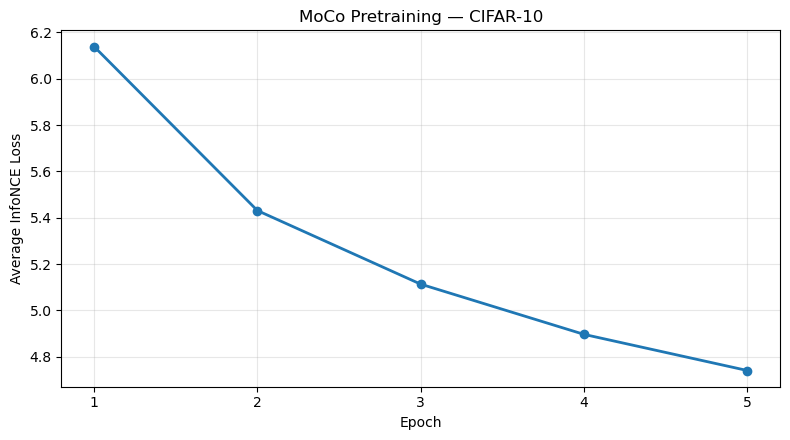

In [17]:
# 绘制epoch曲线
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4.5))

plt.plot(
    range(1, len(epoch_losses) + 1),
    epoch_losses,
    marker="o",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Average InfoNCE Loss")
plt.title("MoCo Pretraining — CIFAR-10")
plt.xticks(range(1, len(epoch_losses) + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [18]:
## 保存

checkpoint_path = project_root / "checkpoints" / "moco_latest.pth"

print("Checkpoint exists:", checkpoint_path.exists())

if checkpoint_path.exists():
    print(
        "Checkpoint size:",
        round(checkpoint_path.stat().st_size / 1024**2, 2),
        "MB"
    )


Checkpoint exists: True
Checkpoint size: 132.25 MB
